<a href="https://colab.research.google.com/github/A-ghori/sklearn/blob/recovery/Gradient_Descent_From_Scratch1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
from sklearn.datasets import make_regression
import numpy as np

In [62]:
X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1, noise=80, random_state=42)

In [63]:
print(X.shape)
print(y.shape)

(4, 1)
(4,)


In [64]:
import matplotlib.pyplot as plt
plt.scatter(X,y)

In [65]:
# Lets apply ordinary least square
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X,y)

LinearRegression()

In [66]:
reg.coef_ # slope

array([-57.99225681])

In [67]:
reg.intercept_ #intercept or bias

np.float64(50.20315110942306)

In [69]:
## Lets apply gradient descent assuming slope is constant m = -57.99225681
## and lets assume the starting value for intercept b = 0

y_pred = ((-57.99225681 * X) + 0)

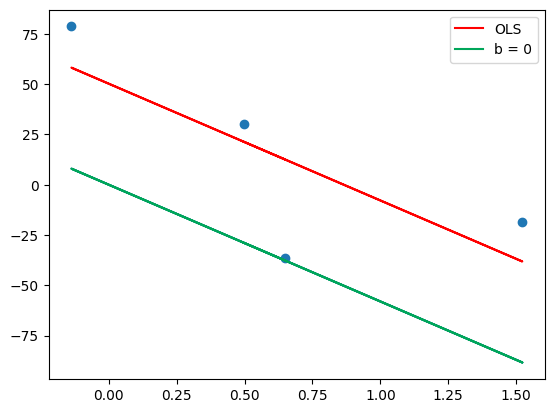

In [70]:
plt.scatter(X,y)
plt.plot(X,y_pred)
plt.plot(X,reg.predict(X), color="red", label="OLS")
plt.plot(X,y_pred, color="#00a65a", label="b = 0")
plt.legend()
plt.show()

-401.62520889381335
4.016252088938134


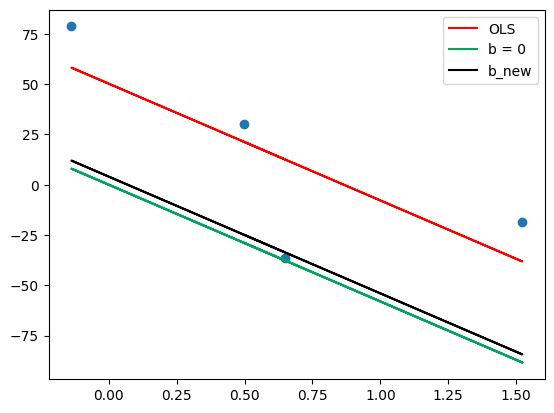

In [71]:
## Now iteration1 m =  -57.99225681 b = 0

m =  -57.99225681
b = 0

loss_slope = -2 * np.sum(y - m * X.ravel() - b)
print(loss_slope)

# for first iteration
lr = 0.01

b_new = b - lr * loss_slope
print(b_new)

y_pred1 = ((-57.99225681 * X) + b_new).reshape(4)
#print("y_pred1", y_pred1)
# now put on the graph
plt.scatter(X,y)
plt.plot(X, y_pred)
plt.plot(X,reg.predict(X), color="red", label="OLS")
plt.plot(X,y_pred, color="#00a65a", label="b = 0")
plt.plot(X, y_pred1, color="black", label="b_new")
plt.legend()
plt.show()



Epoch: 0 : b = 4.016252088938134Loss = 11823.408429786352
Epoch: 10 : b = 30.140095439834575Loss = 4900.594675995058
Epoch: 20 : b = 41.487991371410786Loss = 3594.3059016181837
Epoch: 30 : b = 46.41738634381882Loss = 3347.817923933022
Epoch: 40 : b = 48.55865860614089Loss = 3301.3072868250038
Epoch: 50 : b = 49.48880255424291Loss = 3292.5310398676083
Epoch: 60 : b = 49.89284634606442Loss = 3290.8750206116633
Epoch: 70 : b = 50.06835830423242Loss = 3290.562540825101
Epoch: 80 : b = 50.144598672438775Loss = 3290.503577973879
Epoch: 90 : b = 50.17771660813337Loss = 3290.492452077185
Epoch: 100 : b = 50.19210265702684Loss = 3290.490352694698
Epoch: 110 : b = 50.198351790568054Loss = 3290.4899565552264
Epoch: 120 : b = 50.20106634202726Loss = 3290.489881806351
Epoch: 130 : b = 50.20224551183953Loss = 3290.4898677017377
Epoch: 140 : b = 50.202757729591546Loss = 3290.4898650402906
Epoch: 150 : b = 50.20298023106907Loss = 3290.489864538093
Epoch: 160 : b = 50.203076883141954Loss = 3290.4898644

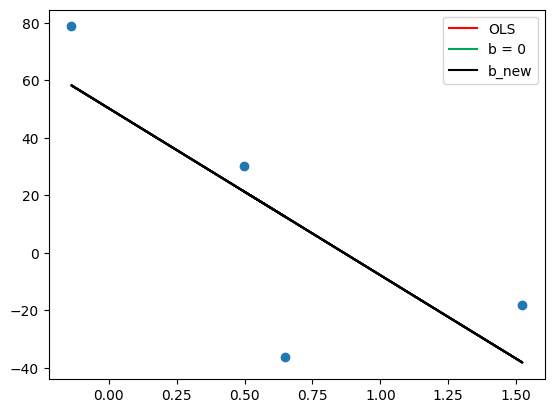

In [73]:
m = -57.99225681
b = 0
lr = 0.01
epochs = 100

loss_history = []
b_history = []


#now see if i pass epoch = 100
epochs = 1000
for epoch in range(epochs):
  # calculate the GD using current b
  loss_slope = -2 * np.sum(y - m * X.ravel() - b)

  # setp 2 update b
  b =  b - lr*loss_slope

  #calculate predictions with updated b
  y_pred = m * X.ravel() + b

  # calculate loss
  loss = np.sum((y - y_pred) ** 2)

  # store values of loss
  loss_history.append(loss)
  b_history.append(b)

  if epoch % 10 == 0:
    print(
        f"Epoch: {epoch} : b = {b}"
        f"Loss = {loss}"
    )

print("Final b:", b)
print(b_history[-1])

y_pred2 = ((m * X) + b_history[-1])
print(y_pred2)
# now put on the graph
plt.scatter(X,y)
plt.plot(X, y_pred)
plt.plot(X,reg.predict(X), color="red", label="OLS")
plt.plot(X,y_pred, color="#00a65a", label="b = 0")
plt.plot(X, y_pred2, color="black", label="b_new")
plt.legend()
plt.show()
